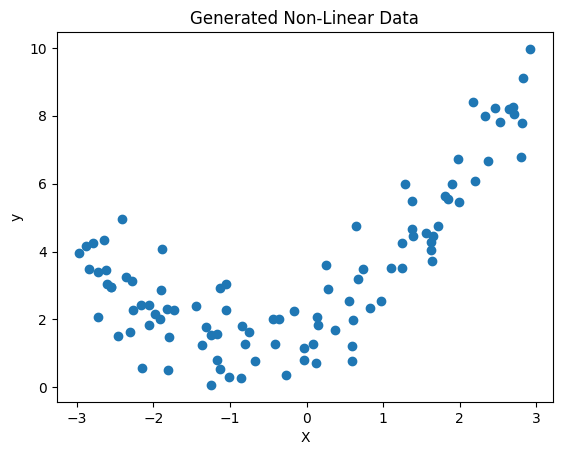

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
# Set seed for reproducibility
np.random.seed(42)

# Generate 100 data points
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X**2 + X + 2 + np.random.randn(m, 1)

# Plot the data
plt.scatter(X, y)
plt.title("Generated Non-Linear Data")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

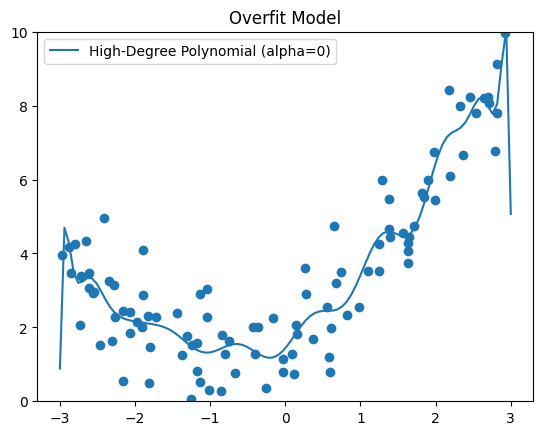

In [7]:


# To apply Ridge, we first need to create the high-degree polynomial features
# 1. Create Polynomial Features (degree 20)
poly_features = PolynomialFeatures(degree=20, include_bias=False)
X_poly = poly_features.fit_transform(X)

# 2. Scale the features
# We fit a scaler on the polynomial features
scaler = StandardScaler()
X_poly_scaled = scaler.fit_transform(X_poly)

# 3. Fit a high-degree model with no regularization (alpha=0 is like LinearRegression)
overfit_model = LinearRegression()
overfit_model.fit(X_poly_scaled, y)


# Before predicting, we must apply the SAME transformations to the new data
X_new = np.linspace(-3, 3, 100).reshape(-1, 1)
X_new_poly = poly_features.transform(X_new)
X_new_poly_scaled = scaler.transform(X_new_poly)

# Make predictions with both models
y_overfit_pred = overfit_model.predict(X_new_poly_scaled)

# Plotting
plt.scatter(X, y)
plt.plot(X_new, y_overfit_pred, label="High-Degree Polynomial (alpha=0)")
plt.title("Overfit Model")
plt.ylim(0, 10) # Limit y-axis for better visualization
plt.legend()
plt.show()






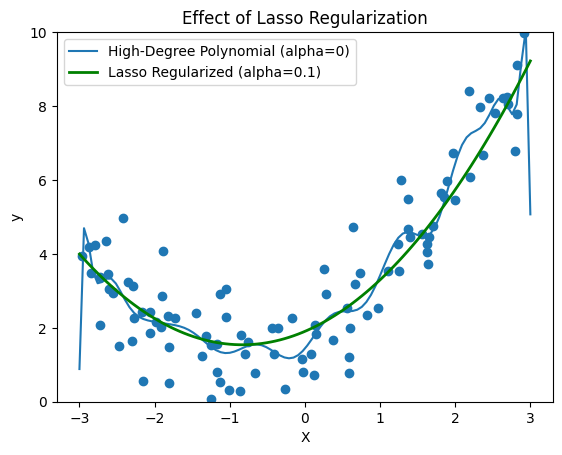

In [9]:
# 3. Fit the Lasso model on the transformed data
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_poly_scaled, y)

# Before predicting, we must apply the SAME transformations to the new data
X_new = np.linspace(-3, 3, 100).reshape(-1, 1)
X_new_poly = poly_features.transform(X_new)
X_new_poly_scaled = scaler.transform(X_new_poly)

# Make predictions with both models
y_overfit_pred = overfit_model.predict(X_new_poly_scaled)
y_lasso_pred = lasso_model.predict(X_new_poly_scaled)

# Plotting
# Plotting the Lasso fit vs the overfit model
plt.scatter(X, y)
plt.plot(X_new, y_overfit_pred, label="High-Degree Polynomial (alpha=0)")
plt.plot(X_new, y_lasso_pred, "g-", linewidth=2, label="Lasso Regularized (alpha=0.1)")
plt.title("Effect of Lasso Regularization")
plt.xlabel("X")
plt.ylabel("y")
plt.ylim(0, 10) # Limit y-axis for better visualization
plt.legend()
plt.show()